# From Pearson's escape to Ranieri's title: the tactical numbers

Companion to [`docs/tactics_pearson_to_ranieri.md`](../docs/tactics_pearson_to_ranieri.md), which tells the story using published tactical analysis.
This notebook checks the main claims with data:

1. **What changed between 2014/15 and 2015/16?** Premier League official team stats (Opta), both seasons, from premierleague.com (`data/external/pl_club_raw.txt`).
2. **What did Ranieri's system look like next to the rest of the league?** StatsBomb 2015/16 event data, all 20 teams.
3. **What changed during 2015/16?** StatsBomb, Leicester's matches 1–19 vs 20–38.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # project folder
REPO = ROOT.parent  # repo root: shared code (src/) and downloaded data (data/raw, data/processed)
FIGS = ROOT / "reports" / "figures"
LEI = "Leicester City"
BLUE, GREY, DARK, MUTED, GOLD = "#1F5FAD", "#B4B2A9", "#3D3D3A", "#6B6A64", "#FDBE11"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
    "axes.grid": True, "grid.color": "#ECEAE4", "grid.linewidth": 0.8, "axes.axisbelow": True,
})
def source(fig, text, y=-0.02):
    fig.text(0.01, y, text, fontsize=8, color="#8A8880")

## 1. 2014/15 vs 2015/16: the same volume of passing, far more xG

Team season totals from premierleague.com (Opta). "Shots" on the site's club page doesn't add up with its own shots-on-target split, so it's left out; shot figures come from the Premier League's [PL30 article](https://www.premierleague.com/en/news/2748139) instead.

In [2]:
HEADERS = {"Attack", "Defence", "Possession", "Physical", "Discipline"}
def parse(line):
    head, body = line.split("#", 1)
    items = [x for x in body.split("|") if x not in HEADERS]
    row, i = {}, 0
    while i < len(items) - 1:
        lab, val = items[i], items[i + 1]
        mm = re.match(r"([\d,\.]+)(?: \(([\d\.]+)%?\))?$", val)
        if not mm:
            i += 1; continue
        key = lab.replace(" (Completed %)", "").replace(" (Scored)", "")
        row.setdefault(key, float(mm.group(1).replace(",", "")))
        if mm.group(2):
            row.setdefault(key + " %", float(mm.group(2)))
        i += 2
    return head.split("@")[1], row

club = pd.DataFrame(dict(parse(l) for l in (ROOT / "data" / "external" / "pl_club_raw.txt").read_text().splitlines() if l.strip()))
club.columns = ["2014/15", "2015/16"]
club["change %"] = ((club["2015/16"] / club["2014/15"] - 1) * 100).round(0)
club.loc[["Goals", "XG", "Goals Conceded", "Passes", "Long Passes", "Long Passes %", "Crosses", "Aerial Duels Won",
          "Dribbles", "Dribbles %", "Touches in the Opposition Box", "Interceptions", "Clearances", "Blocks", "Penalties", "Fouls"]]

,2014/15,2015/16,change %
Goals,46.00,68.00,48.0
XG,46.86,69.31,48.0
Goals Conceded,55.00,36.00,-35.0
Passes,13343.00,13370.00,0.0
Long Passes,2706.00,2695.00,-0.0
Long Passes %,38.00,37.00,-3.0
Crosses,628.00,535.00,-15.0
Aerial Duels Won,891.00,713.00,-20.0
Dribbles,686.00,795.00,16.0
Dribbles %,50.00,54.00,8.0


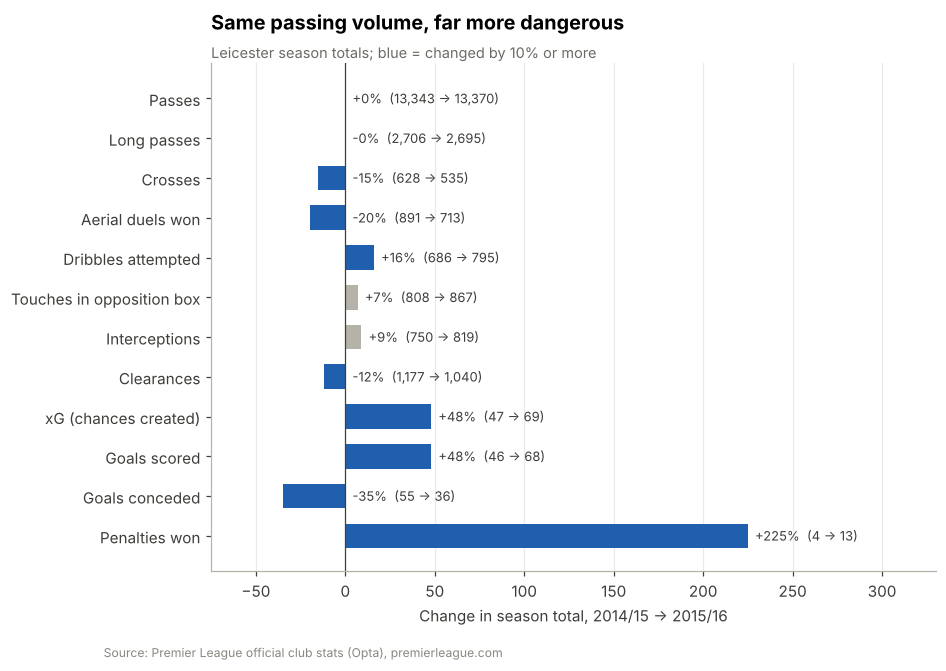

In [3]:
ROWS = [("Passes", "Passes"), ("Long Passes", "Long passes"), ("Crosses", "Crosses"), ("Aerial Duels Won", "Aerial duels won"),
        ("Dribbles", "Dribbles attempted"), ("Touches in the Opposition Box", "Touches in opposition box"),
        ("Interceptions", "Interceptions"), ("Clearances", "Clearances"),
        ("XG", "xG (chances created)"), ("Goals", "Goals scored"), ("Goals Conceded", "Goals conceded"), ("Penalties", "Penalties won")]
ch = pd.Series({lab: club.loc[k, "change %"] for k, lab in ROWS})[::-1]
fig, ax = plt.subplots(figsize=(8.5, 6))
colors = [BLUE if abs(v) >= 10 else GREY for v in ch.values]
ax.barh(ch.index, ch.values, color=colors, height=0.62)
ax.axvline(0, color=DARK, lw=0.8)
for y, (lab, v) in enumerate(ch.items()):
    k = dict((b, a) for a, b in ROWS)[lab]
    txt = f"{v:+.0f}%  ({club.loc[k, '2014/15']:,.0f} → {club.loc[k, '2015/16']:,.0f})"
    ax.text(max(v, 0) + 4, y, txt, va="center", ha="left", fontsize=8.5, color=DARK)
ax.set_xlim(-75, 330)
ax.set_xlabel("Change in season total, 2014/15 → 2015/16")
ax.grid(axis="y", visible=False)
ax.set_title("Same passing volume, far more dangerous", pad=22)
ax.annotate("Leicester season totals; blue = changed by 10% or more", xy=(0, 1.01), xycoords="axes fraction", fontsize=9.5, color=MUTED)
source(fig, "Source: Premier League official club stats (Opta), premierleague.com")
fig.savefig(FIGS / "17_team_2014_15_vs_2015_16.png"); plt.show()

## 2. Ranieri's system next to the rest of the league (StatsBomb 2015/16)

Definitions:
- **Starting shape:** from each match's starting positions (number of defenders, midfielders, forwards).
- **PPDA** (passes per defensive action): opponent passes in their own 60% of the pitch divided by our tackles, interceptions and fouls in that area. **Lower = more aggressive pressing.**
- **Defensive action height:** average distance from own goal (in StatsBomb's 120-unit pitch) of tackles, interceptions, fouls and ball recoveries.
- **Long-pass share:** open-play passes of 35+ yards as a share of all open-play passes.
- **Counter-attack shots:** shots from possessions StatsBomb tags "From Counter".

In [4]:
DATA = REPO / "data" / "processed" / "2_27"
e = pd.read_parquet(DATA / "events.parquet")
m = pd.read_parquet(REPO / "data" / "raw" / "2_27" / "matches.parquet")
lu = pd.read_parquet(REPO / "data" / "raw" / "2_27" / "lineups.parquet")

starters = lu[(lu["from"] == "00:00") & (lu.from_period == 1) & (lu.position != "Goalkeeper")]
def shape(g):
    d = g.position.str.contains("Back").sum()
    f = g.position.str.contains("Forward|Striker").sum()
    return f"{d}-{len(g) - d - f}-{f}"
shapes = starters.groupby(["team", "match_id"]).apply(shape)
print("Leicester starting shapes:", shapes.loc[LEI].value_counts().to_dict())
print("Teams' most-used shape share:", (shapes.groupby(level=0).agg(lambda s: s.value_counts().iloc[0] / len(s)) * 100).round(0).sort_values(ascending=False).head(5).to_dict())

Leicester starting shapes: {'4-4-2': 33, '4-5-1': 5}
Teams' most-used shape share: {'Arsenal': 100.0, 'Chelsea': 100.0, 'Stoke City': 100.0, 'Tottenham Hotspur': 97.0, 'Everton': 92.0}


In [5]:
other = {}
for r in m.itertuples():
    other[(r.match_id, r.home_team)] = r.away_team
    other[(r.match_id, r.away_team)] = r.home_team
e["opp"] = [other[k] for k in zip(e.match_id, e.team)]
DEF = ((e.type == "Duel") & (e.duel_type == "Tackle")) | e.type.isin(["Interception", "Foul Committed"])
passes = e[e.type == "Pass"]
open_play = passes[passes.pass_type.isna() | (passes.pass_type == "Recovery")]
shots = e[e.type == "Shot"].assign(xg=lambda d: d.shot_statsbomb_xg.astype(float))

T = pd.DataFrame({
    "Possession (pass share %)": passes.groupby("team").size() / (passes.groupby("team").size() + passes.groupby("opp").size()) * 100,
    "Long-pass share %": open_play.assign(l=open_play.pass_length.astype(float) >= 35).groupby("team").l.mean() * 100,
    "Counter-attack shots": shots[shots.play_pattern == "From Counter"].groupby("team").size(),
    "Pressures per game": e[e.type == "Pressure"].groupby("team").size() / 38,
    "PPDA": passes[passes.start_x <= 72].groupby("opp").size() / e[DEF & (e.start_x >= 48)].groupby("team").size(),
    "Defensive action height": e[DEF | (e.type == "Ball Recovery")].groupby("team").start_x.mean(),
    "Shots conceded per game": shots.groupby("opp").size() / 38,
    "xG per shot conceded": shots.groupby("opp").xg.mean(),
})
rank = T.rank(ascending=False, method="min").astype(int)
pd.DataFrame({"Leicester": T.loc[LEI].round(3), "rank (1 = highest)": rank.loc[LEI], "league median": T.median().round(3)})

,Leicester,rank (1 = highest),league median
Possession (pass share %),42.455,18,49.356
Long-pass share %,16.763,4,14.174
Counter-attack shots,38.000,1,21.000
Pressures per game,163.974,3,150.276
PPDA,16.329,8,15.962
Defensive action height,50.905,9,50.619
Shots conceded per game,13.605,9,13.421
xG per shot conceded,0.089,16,0.097


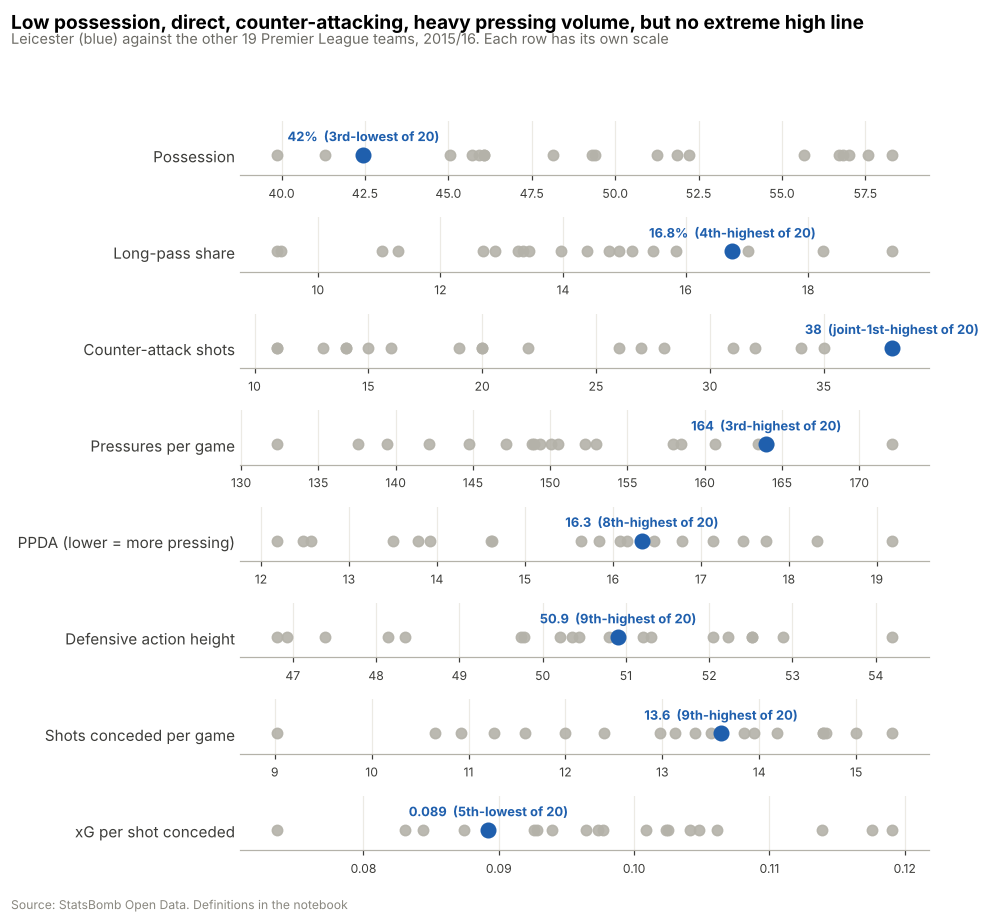

In [6]:
ORDER = [("Possession (pass share %)", "Possession", "%.0f%%"), ("Long-pass share %", "Long-pass share", "%.1f%%"),
         ("Counter-attack shots", "Counter-attack shots", "%.0f"), ("Pressures per game", "Pressures per game", "%.0f"),
         ("PPDA", "PPDA (lower = more pressing)", "%.1f"), ("Defensive action height", "Defensive action height", "%.1f"),
         ("Shots conceded per game", "Shots conceded per game", "%.1f"), ("xG per shot conceded", "xG per shot conceded", "%.3f")]
fig, axes = plt.subplots(len(ORDER), 1, figsize=(9, 7.6), sharex=False)
for ax, (col, lab, fmt) in zip(axes, ORDER):
    v = T[col]
    ax.scatter(v.drop(LEI), np.zeros(19), s=46, color=GREY, alpha=0.9, zorder=2)
    ax.scatter([v[LEI]], [0], s=90, color=BLUE, zorder=3)
    r = rank.loc[LEI, col]
    ordn = lambda k: f"{k}{'st' if k == 1 else 'nd' if k == 2 else 'rd' if k == 3 else 'th'}"
    tie = "joint-" if (v == v[LEI]).sum() > 1 else ""
    pos = f"{tie}{ordn(r)}-highest" if r <= 10 else f"{tie}{ordn(21 - r)}-lowest"
    ax.annotate(f"{fmt % v[LEI]}  ({pos} of 20)",
                (v[LEI], 0), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8.5, color=BLUE, fontweight="bold")
    ax.set_yticks([0], [lab])
    ax.set_ylim(-0.6, 1.0)
    pad = (v.max() - v.min()) * 0.06
    ax.set_xlim(v.min() - pad, v.max() + pad)
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
fig.suptitle("Low possession, direct, counter-attacking, heavy pressing volume, but no extreme high line",
             x=0.01, ha="left", fontsize=12.5, fontweight="bold", y=1.055)
fig.text(0.01, 1.015, "Leicester (blue) against the other 19 Premier League teams, 2015/16. Each row has its own scale",
         fontsize=9.5, color=MUTED)
fig.tight_layout(rect=(0, 0, 1, 0.99))
source(fig, "Source: StatsBomb Open Data. Definitions in the notebook")
fig.savefig(FIGS / "18_leicester_tactical_profile.png"); plt.show()

## 3. The mid-season change

Wilson (New Statesman) and others describe Ranieri turning more pragmatic after Leicester kept conceding early in the season.
The data shows what that looked like.

In [7]:
lm = m[(m.home_team == LEI) | (m.away_team == LEI)].sort_values("match_date").reset_index(drop=True)
lm["n"] = lm.index + 1
num = dict(zip(lm.match_id, lm.n))
el = e[e.match_id.isin(num)].assign(n=lambda d: d.match_id.map(num))
rows = []
for n, g in el.groupby("n"):
    p = g[g.type == "Pass"]
    s = g[(g.type == "Shot") & (g.team != LEI)]
    d = DEF.loc[g.index]
    lei_def_high = g[(g.team == LEI) & d & (g.start_x >= 48)].shape[0]
    r = lm.loc[n - 1]
    ga = r.away_score if r.home_team == LEI else r.home_score
    rows.append({"n": n, "opp_passes_own60": ((p.team != LEI) & (p.start_x <= 72)).sum(), "lei_def_high": lei_def_high,
                 "pressures": ((g.type == "Pressure") & (g.team == LEI)).sum(), "shots_against": len(s),
                 "xga": s.shot_statsbomb_xg.astype(float).sum(), "conceded": int(ga)})
pm = pd.DataFrame(rows)
pm["half"] = np.where(pm.n <= 19, "Matches 1–19", "Matches 20–38")
halves = pm.groupby("half").agg(ppda=("opp_passes_own60", "sum"), dh=("lei_def_high", "sum"), pressures=("pressures", "mean"),
                                shots_against=("shots_against", "mean"), xga=("xga", "mean"), xga_tot=("xga", "sum"),
                                shots_tot=("shots_against", "sum"), conceded=("conceded", "sum"),
                                clean_sheets=("conceded", lambda s: (s == 0).sum()))
halves["ppda"] = halves.ppda / halves.dh
halves["xg_per_shot_against"] = halves.xga_tot / halves.shots_tot
halves.drop(columns=["dh", "xga_tot", "shots_tot"]).round(3).T

half,Matches 1–19,Matches 20–38
ppda,18.387,14.507
pressures,153.053,174.895
shots_against,13.158,14.053
xga,1.365,1.063
conceded,25.000,11.000
clean_sheets,4.000,11.000
xg_per_shot_against,0.104,0.076


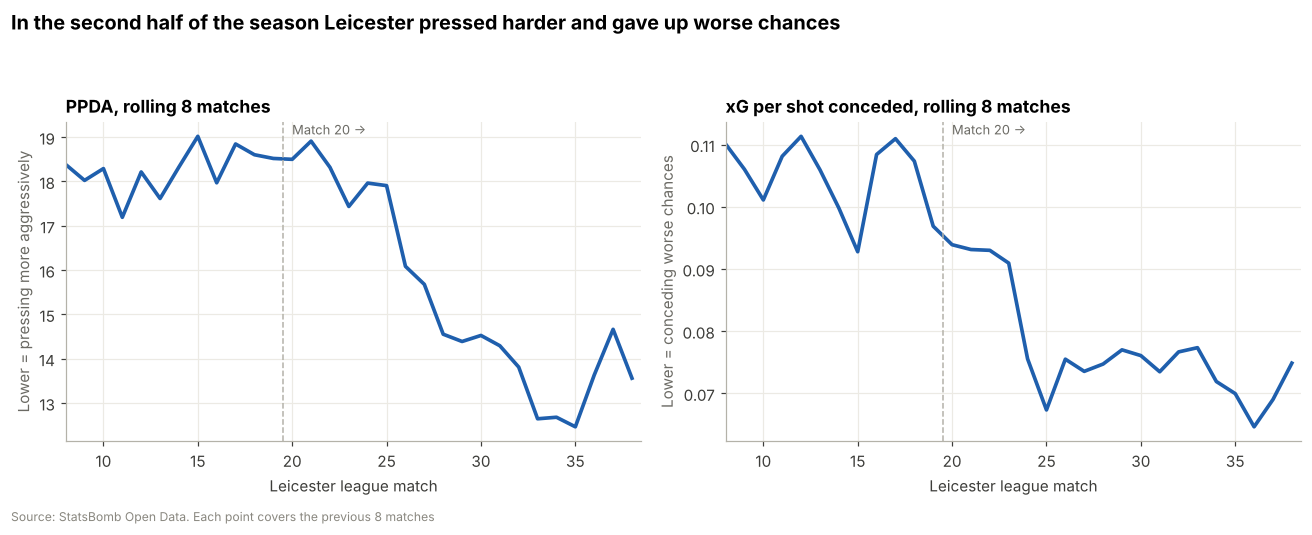

In [8]:
roll = pm.set_index("n")
w = 8
ppda_r = roll.opp_passes_own60.rolling(w).sum() / roll.lei_def_high.rolling(w).sum()
xgps_r = roll.xga.rolling(w).sum() / roll.shots_against.rolling(w).sum()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for ax, s, lab, note in [(axes[0], ppda_r, "PPDA, rolling 8 matches", "Lower = pressing more aggressively"),
                         (axes[1], xgps_r, "xG per shot conceded, rolling 8 matches", "Lower = conceding worse chances")]:
    ax.plot(s.index, s.values, color=BLUE, lw=2.4)
    ax.axvline(19.5, color=GREY, lw=1, ls="--")
    ax.text(19.8, ax.get_ylim()[1], " Match 20 →", va="top", fontsize=8.5, color=MUTED)
    ax.set_title(lab, fontsize=11.5)
    ax.set_ylabel(note, color=MUTED)
    ax.set_xlabel("Leicester league match")
    ax.set_xlim(8, 38.5)
fig.suptitle("In the second half of the season Leicester pressed harder and gave up worse chances", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.06)
fig.tight_layout()
source(fig, "Source: StatsBomb Open Data. Each point covers the previous 8 matches")
fig.savefig(FIGS / "19_mid_season_change.png"); plt.show()

## Summary

- **Ranieri didn't change how much Leicester passed.** Passes (13,343 → 13,370) and long passes (2,706 → 2,695) were almost identical to Pearson's season, and possession stayed around 42–43%. Leicester were already a direct, low-possession side.
- **He changed what the passes produced.** xG rose from 46.9 to 69.3 (+48%), goals from 46 to 68, penalties won from 4 to 13, and dribbles from 686 to 795. Crosses (−15%) and aerial duels won (−20%) fell: less hitting Ulloa in the air, more running in behind and on the ground.
- **The system, by the numbers:** a 4-4-2 starting shape in 33 of 38 matches; 18th of 20 for possession; 4th for long-pass share; joint-1st for counter-attack shots; 3rd for pressures per game. But Leicester's PPDA and defensive action height were mid-table, so this was a compact mid-block, not a high press.
- **The defence:** Leicester conceded an average number of shots (13.6 per game) but low-quality ones (5th-lowest xG per shot).
- **During the season:** from match 20 Leicester pressed harder (PPDA 18.4 → 14.5, pressures per game 153 → 175) and the chances they conceded got much worse (xG per shot 0.104 → 0.076). Goals conceded fell from 25 to 11, and clean sheets rose from 4 to 11.

**Limitations:** there's no 2014/15 event data, so the formation, pressing and line-height comparisons only cover 2015/16. Rolling averages smooth over individual matches.